In [4]:
import os, sys, json, time, re, warnings, shutil, math
from pathlib import Path
warnings.filterwarnings("ignore")
try:
    import imblearn, xgboost
except ImportError:
    get_ipython().run_line_magic("pip", "install -q imbalanced-learn xgboost")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
from joblib import Parallel, delayed, dump
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import f_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, auc, confusion_matrix, classification_report)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# ---------------- configuration ----------------
SEED = 42
MAX_PER_CLASS = int(os.environ.get("MAX_PER_CLASS", 0)) or None   # None = use every image. e.g. 300 for a quick run
OUT = Path(os.environ.get("OUT_DIR", "outputs"))
(OUT / "figures").mkdir(parents=True, exist_ok=True); (OUT / "tables").mkdir(exist_ok=True)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold"})
RES = {"config": {"seed": SEED, "max_per_class": MAX_PER_CLASS}, "text": {}}   # everything the report/slides need
def savefig(name):
    plt.savefig(OUT / "figures" / name, bbox_inches="tight"); plt.show()
print("Output folder:", OUT.resolve())

Output folder: /kaggle/working/outputs


## 1. Feature extractor (shared with the Streamlit demo)
Written to `plant_features.py` so the notebook and the demo app use **identical** preprocessing (no train/serve skew).

In [5]:
%%writefile plant_features.py
"""Hand-crafted image features for classical ML on leaf images (shared by notebook + Streamlit app)."""
import numpy as np
import cv2
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

IMG_SIZE = 128

FEATURE_NAMES = (
    ["rgb_mean_r", "rgb_mean_g", "rgb_mean_b", "rgb_std_r", "rgb_std_g", "rgb_std_b",
     "hsv_mean_h", "hsv_mean_s", "hsv_mean_v", "hsv_std_h", "hsv_std_s", "hsv_std_v"]
    + [f"hhist_{i}" for i in range(8)] + [f"shist_{i}" for i in range(8)] + [f"vhist_{i}" for i in range(8)]
    + ["glcm_contrast", "glcm_dissimilarity", "glcm_homogeneity", "glcm_energy", "glcm_correlation"]
    + [f"lbp_{i}" for i in range(10)]
    + ["exg_mean", "green_frac", "yellow_frac", "brown_frac", "edge_density"]
)


def extract_features(rgb):
    """rgb: uint8 array (H, W, 3) in RGB order -> float32 vector of len(FEATURE_NAMES)."""
    img = cv2.resize(np.ascontiguousarray(rgb, dtype=np.uint8), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    f = img.astype(np.float32)
    feats = list(f.mean((0, 1))) + list(f.std((0, 1)))                      # colour statistics (RGB)
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    h = hsv.reshape(-1, 3).astype(np.float32)
    feats += list(h.mean(0)) + list(h.std(0))                               # colour statistics (HSV)
    for ch, top in zip(range(3), (180, 256, 256)):                           # 8-bin H, S, V histograms
        hist = np.histogram(hsv[..., ch], bins=8, range=(0, top))[0].astype(np.float32)
        feats += list(hist / hist.sum())
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    glcm = graycomatrix((gray // 8).astype(np.uint8), [1], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                        levels=32, symmetric=True, normed=True)             # GLCM texture
    for p in ("contrast", "dissimilarity", "homogeneity", "energy", "correlation"):
        feats.append(float(graycoprops(glcm, p).mean()))
    lbp = local_binary_pattern(gray, 8, 1, "uniform")                       # LBP texture histogram
    hist = np.bincount(lbp.astype(int).ravel(), minlength=10)[:10].astype(np.float32)
    feats += list(hist / hist.sum())
    r, g, b = f[..., 0], f[..., 1], f[..., 2]
    H, S = hsv[..., 0], hsv[..., 1]
    feats.append(float((2 * g - r - b).mean()))                             # excess-green index
    feats.append(float(((H >= 35) & (H <= 85) & (S > 40)).mean()))          # healthy-green pixel fraction
    feats.append(float(((H >= 20) & (H < 35) & (S > 60)).mean()))           # yellowing fraction
    feats.append(float(((H >= 5) & (H < 20) & (S > 50)).mean()))            # brown / necrotic fraction
    feats.append(float((cv2.Canny(gray, 100, 200) > 0).mean()))             # edge density
    return np.array(feats, dtype=np.float32)


class BalancedXGB(XGBClassifier):
    """XGBoost with balanced sample weights computed inside fit() (works in any CV loop).
    Lives in this module so the saved model can be unpickled by the Streamlit app."""
    def fit(self, X, y, **kw):
        kw["sample_weight"] = compute_sample_weight("balanced", y)
        return super().fit(X, y, **kw)

Overwriting plant_features.py


In [6]:
from plant_features import extract_features, FEATURE_NAMES, IMG_SIZE
print(len(FEATURE_NAMES), "features per image, images resized to", IMG_SIZE, "x", IMG_SIZE)

56 features per image, images resized to 128 x 128


# WEEK 1 — Problem Understanding & Data Exploration
## 2. Dataset: source, size, structure
**Source:** PlantVillage dataset, Kaggle `emmarex/plantdisease` (lab-captured leaf photos of pepper, potato and tomato; one folder per class, folder name = label).

In [7]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
def find_dataset():
    for c in [os.environ.get("DATA_DIR"), "/kaggle/input/plantdisease", "PlantVillage", "data"]:
        if c and Path(c).exists():
            return Path(c)
    try:                                     # official download via the Kaggle hub (needs Kaggle credentials)
        import kagglehub
        return Path(kagglehub.dataset_download("emmarex/plantdisease"))
    except Exception as e:
        raise SystemExit("Dataset not found. Add 'emmarex/plantdisease' as a Kaggle input, or set DATA_DIR to the "
                         f"folder that contains the class folders. ({e})")

ROOT = find_dataset()
paths = sorted(p for p in ROOT.rglob("*") if p.suffix.lower() in IMG_EXT)
meta = pd.DataFrame({"path": [str(p) for p in paths], "label": [p.parent.name for p in paths], "file": [p.name for p in paths]})
n_raw = len(meta)
meta = meta.drop_duplicates(["label", "file"]).reset_index(drop=True)      # the Kaggle zip can contain a nested duplicate copy
dup_dropped = n_raw - len(meta)
if MAX_PER_CLASS:
    meta = (meta.groupby("label", group_keys=False)
                .apply(lambda d: d.sample(min(len(d), MAX_PER_CLASS), random_state=SEED)).reset_index(drop=True))
print(f"Root: {ROOT}\nImages found: {n_raw} | duplicate file copies dropped: {dup_dropped} | used: {len(meta)}")

Root: /kaggle/input/datasets/emmarex/plantdisease
Images found: 41276 | duplicate file copies dropped: 20638 | used: 20638


,class,plant,images,share_%
0,Tomato - YellowLeaf Curl Virus,Tomato,3208,15.54
1,Tomato - Bacterial spot,Tomato,2127,10.31
2,Tomato - Late blight,Tomato,1909,9.25
3,Tomato - Septoria leaf spot,Tomato,1771,8.58
4,Tomato - Spider mites Two spotted spider mite,Tomato,1676,8.12
5,Tomato - healthy,Tomato,1591,7.71
6,Pepper - healthy,Pepper,1478,7.16
7,Tomato - Target Spot,Tomato,1404,6.80
8,Potato - Early blight,Potato,1000,4.85
9,Potato - Late blight,Potato,1000,4.85


Classes: 15 | plants: ['Pepper', 'Potato', 'Tomato'] | imbalance ratio (max/min): 21.1x


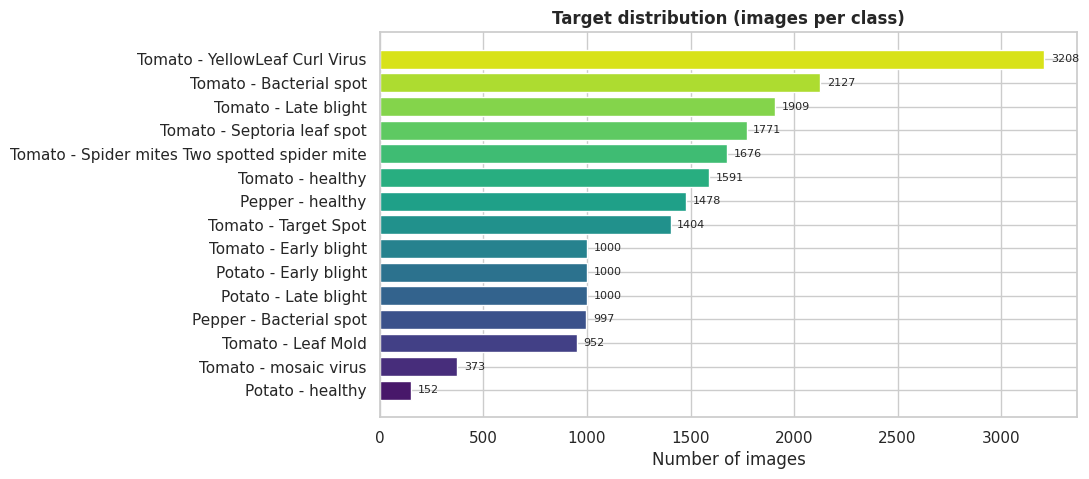

In [8]:
def split_name(c):
    """'Tomato__Tomato_YellowLeaf__Curl_Virus' -> ('Tomato', 'YellowLeaf Curl Virus')"""
    s = c.replace("Pepper__bell", "Pepper")
    m = re.match(r"^(Pepper|Potato|Tomato)_+(.*)$", s)
    if not m:
        return "Unknown", re.sub(r"_+", " ", s).strip()
    dis = re.sub(r"^Tomato_", "", m.group(2))
    return m.group(1), re.sub(r"_+", " ", dis).strip()
def pretty(c):
    p, d = split_name(c)
    return c.replace("_", " ") if p == "Unknown" else f"{p} - {d}"

counts = meta["label"].value_counts()
cls_tbl = pd.DataFrame({"class": [pretty(c) for c in counts.index], "plant": [split_name(c)[0] for c in counts.index],
                        "images": counts.values, "share_%": (counts.values / counts.sum() * 100).round(2)})
display(cls_tbl)
print(f"Classes: {len(counts)} | plants: {sorted(cls_tbl.plant.unique())} | imbalance ratio (max/min): {counts.max()/counts.min():.1f}x")

fig, ax = plt.subplots(figsize=(9, 5))
cls_sorted = cls_tbl.sort_values("images")
ax.barh(cls_sorted["class"], cls_sorted["images"], color=sns.color_palette("viridis", len(cls_sorted)))
for i, v in enumerate(cls_sorted["images"]): ax.text(v + counts.max()*0.01, i, str(v), va="center", fontsize=8)
ax.set_xlabel("Number of images"); ax.set_title("Target distribution (images per class)")
savefig("class_distribution.png")

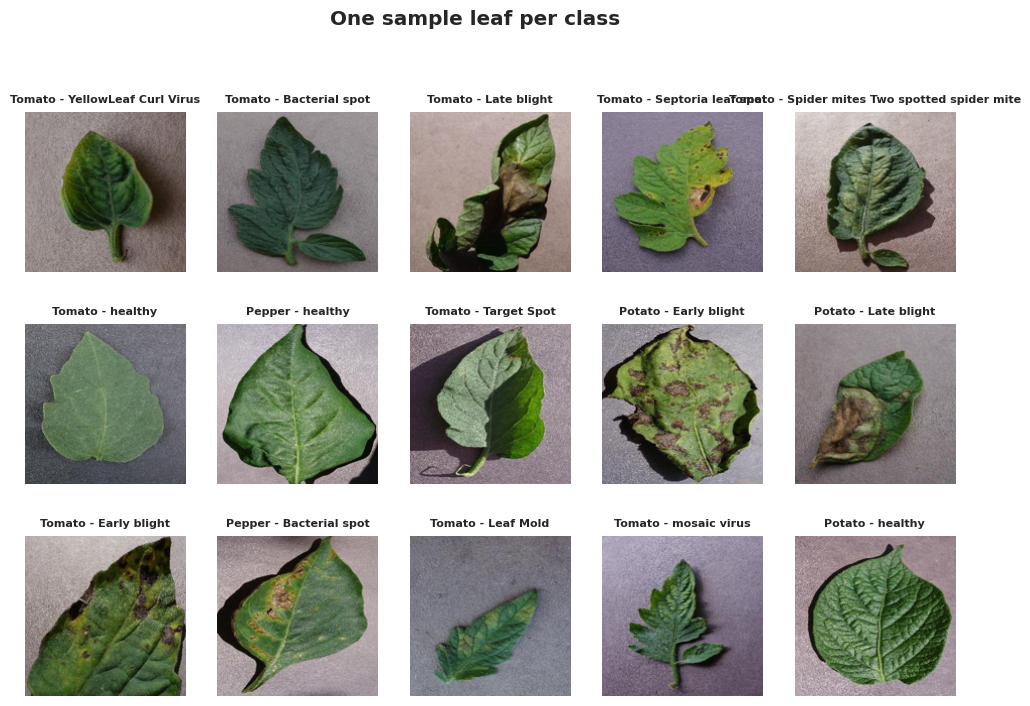

In [9]:
# one sample image per class
labels_sorted = list(counts.index)
ncol = 5; nrow = math.ceil(len(labels_sorted) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(12, 2.6 * nrow))
for ax in np.ravel(axes): ax.axis("off")
for ax, lab in zip(np.ravel(axes), labels_sorted):
    p = meta.loc[meta.label == lab, "path"].iloc[0]
    ax.imshow(Image.open(p).convert("RGB").resize((160, 160))); ax.set_title(pretty(lab), fontsize=8)
plt.suptitle("One sample leaf per class", y=1.0, fontweight="bold")
savefig("sample_images.png")

## 3. Feature extraction (image → tabular)
Each image becomes a 56-dimensional numeric vector. Groups: **colour statistics** (RGB/HSV mean & std), **colour histograms** (8-bin H/S/V), **texture** (GLCM ×5, LBP ×10), **lesion-colour indices** (excess-green, green/yellow/brown pixel fraction), **edge density**. Features are cached to CSV so re-runs are instant.

In [10]:
def _work(p):
    try:
        im = Image.open(p); w, h = im.size
        return (w, h, *extract_features(np.asarray(im.convert("RGB"))))
    except Exception:
        return None

CACHE = OUT / f"features_{MAX_PER_CLASS or 'all'}.csv"
if CACHE.exists():
    df = pd.read_csv(CACHE); print("Loaded cached features:", CACHE)
else:
    t0 = time.time()
    try:
        from tqdm.auto import tqdm; it = tqdm(meta["path"], desc="extracting")
    except ImportError:
        it = meta["path"]
    rows = Parallel(n_jobs=-1, batch_size=32)(delayed(_work)(p) for p in it)
    ok = [i for i, r in enumerate(rows) if r is not None]
    df = pd.DataFrame([rows[i] for i in ok], columns=["width", "height"] + FEATURE_NAMES)
    df.insert(0, "label", meta.loc[ok, "label"].values); df.insert(0, "path", meta.loc[ok, "path"].values)
    df.to_csv(CACHE, index=False); print(f"Extraction took {(time.time()-t0)/60:.1f} min")
corrupted = len(meta) - len(df)
X_df = df[FEATURE_NAMES].astype(float)
size_counts = (df["width"].astype(str) + "x" + df["height"].astype(str)).value_counts()
print(f"Feature matrix: {X_df.shape} | unreadable images skipped: {corrupted}\nOriginal image sizes:\n{size_counts.head()}")

extracting:   0%|          | 0/20638 [00:00<?, ?it/s]

Extraction took 5.1 min
Feature matrix: (20638, 56) | unreadable images skipped: 0
Original image sizes:
256x256    20638
Name: count, dtype: int64


### Dataset description
| Item | Value |
|---|---|
| Observations | number of readable images (printed above) |
| Raw data type | RGB JPEG photographs, uniform size, lab background |
| **Feature types** | 56 **continuous numeric** features (no categorical features) in 6 families |
| **Target variable** | `label` — categorical, multi-class (plant + disease or *healthy*) |
| Task | Multi-class classification |

In [11]:
def fam(n):
    if n.startswith(("rgb", "hsv")): return "Colour statistics"
    if n.startswith(("hhist", "shist", "vhist")): return "Colour histograms"
    if n.startswith(("glcm", "lbp")): return "Texture (GLCM/LBP)"
    if n.startswith("edge"): return "Edge density"
    return "Lesion-colour indices"
FAMILY = {n: fam(n) for n in FEATURE_NAMES}
fam_counts = pd.Series(FAMILY).value_counts()
display(fam_counts.rename("n_features").to_frame())
display(X_df.describe().T.round(3).head(12))

RES["dataset"] = dict(source="Kaggle emmarex/plantdisease (PlantVillage)", n_raw_files=int(n_raw), dup_dropped=int(dup_dropped),
    n_images=int(len(df)), corrupted=int(corrupted), n_classes=int(df.label.nunique()), plants=sorted(cls_tbl.plant.unique().tolist()),
    class_counts={pretty(k): int(v) for k, v in df.label.value_counts().items()},
    imbalance_ratio=float(counts.max() / counts.min()), min_class=pretty(counts.idxmin()), max_class=pretty(counts.idxmax()),
    min_count=int(counts.min()), max_count=int(counts.max()), size_counts={k: int(v) for k, v in size_counts.head(3).items()})
RES["features"] = dict(n=len(FEATURE_NAMES), families={k: int(v) for k, v in fam_counts.items()})

,n_features
Colour histograms,24
Texture (GLCM/LBP),15
Colour statistics,12
Lesion-colour indices,4
Edge density,1


,count,mean,std,min,25%,50%,75%,max
rgb_mean_r,20638.0,117.121,18.023,8.314,106.898,117.633,127.390,194.354
rgb_mean_g,20638.0,121.261,17.280,8.678,111.068,120.698,130.343,201.698
rgb_mean_b,20638.0,105.010,17.470,5.753,94.368,106.011,115.976,188.793
rgb_std_r,20638.0,42.168,10.855,11.520,35.683,42.999,49.336,93.588
rgb_std_g,20638.0,36.000,9.682,8.790,28.821,35.511,42.506,90.127
rgb_std_b,20638.0,46.742,10.152,11.934,41.003,46.997,53.537,85.488
hsv_mean_h,20638.0,81.191,30.905,6.787,57.667,90.312,103.091,155.851
hsv_mean_s,20638.0,62.342,17.084,13.311,50.360,60.236,72.707,229.784
hsv_mean_v,20638.0,128.284,17.575,8.817,118.502,128.420,137.673,207.051
hsv_std_h,20638.0,47.124,15.889,4.373,37.530,49.747,59.637,83.303


## 4. Missing-value analysis
Two levels: (a) **images** that could not be read, (b) **NaN / infinite** values in the feature matrix.

Unreadable images: 0 | NaN cells: 0 | Inf cells: 0 | zero-variance features: []


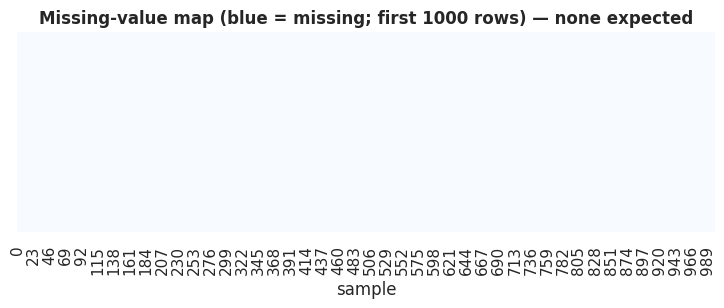

In [12]:
n_nan = int(X_df.isna().sum().sum()); n_inf = int(np.isinf(X_df.values).sum())
zero_var = [c for c in X_df.columns if X_df[c].std() == 0]
print(f"Unreadable images: {corrupted} | NaN cells: {n_nan} | Inf cells: {n_inf} | zero-variance features: {zero_var}")
fig, ax = plt.subplots(figsize=(9, 2.6)); sns.heatmap(X_df.isna().T.iloc[:, :1000], cbar=False, yticklabels=False, ax=ax, cmap="Blues")
ax.set_title("Missing-value map (blue = missing; first 1000 rows) — none expected"); ax.set_xlabel("sample"); savefig("missing_values.png")
RES["eda"] = dict(missing_cells=n_nan, inf_cells=n_inf, zero_variance=zero_var)

**Finding:** feature extraction is deterministic and fully defined for every readable image, so there is no missing data to impute. Any unreadable file is simply dropped (count shown above); imputation is therefore not required.

## 5. Outlier detection (IQR rule)
A value is flagged if it lies outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.

Cells flagged: 4.94% | rows with >=1 flagged feature: 76.4%


,% outliers
vhist_7,18.80
hhist_3,17.26
hhist_4,15.02
hhist_5,14.04
brown_frac,13.88
hhist_0,13.74
vhist_6,11.50
shist_7,11.00
shist_6,9.10
yellow_frac,8.15


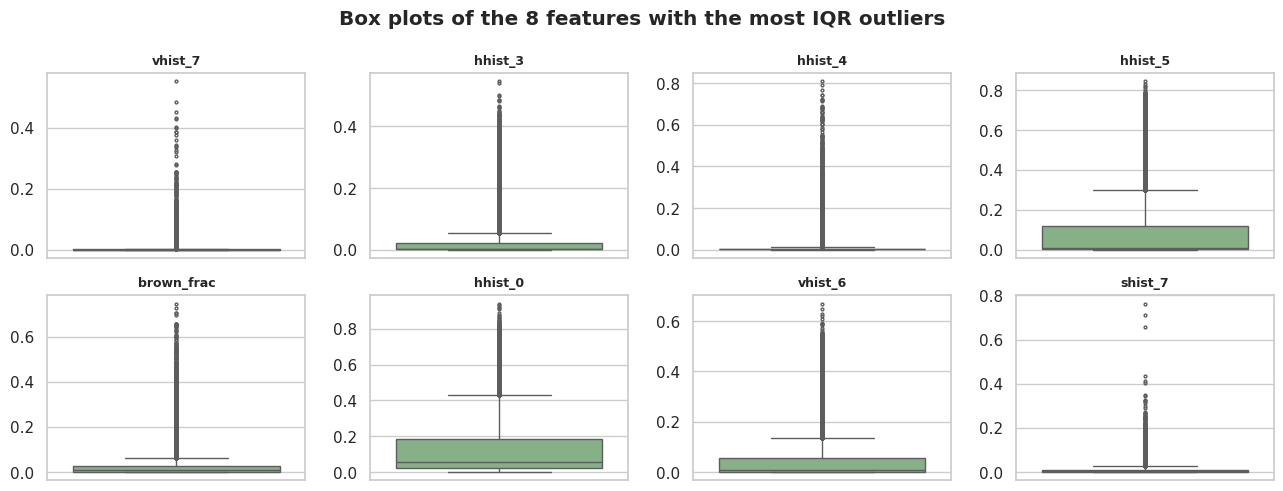

In [13]:
Q1, Q3 = X_df.quantile(.25), X_df.quantile(.75); IQR = Q3 - Q1
mask = (X_df < Q1 - 1.5 * IQR) | (X_df > Q3 + 1.5 * IQR)
out_pct = (mask.mean() * 100).sort_values(ascending=False)
rows_any = mask.any(axis=1).mean() * 100
print(f"Cells flagged: {mask.values.mean()*100:.2f}% | rows with >=1 flagged feature: {rows_any:.1f}%")
display(out_pct.head(10).round(2).rename("% outliers").to_frame())
top8 = out_pct.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for ax, c in zip(axes.ravel(), top8):
    sns.boxplot(y=X_df[c], ax=ax, color="#7fb77e", fliersize=2); ax.set_title(c, fontsize=9); ax.set_ylabel("")
plt.suptitle("Box plots of the 8 features with the most IQR outliers", fontweight="bold"); plt.tight_layout(); savefig("outliers_boxplot.png")
RES["eda"].update(outlier_cell_pct=float(mask.values.mean() * 100), outlier_row_pct=float(rows_any),
                  outlier_top=[{"feature": k, "pct": float(v)} for k, v in out_pct.head(8).items()])

**Decision:** outliers are **kept**. They are genuine biological variation (e.g. heavily diseased or very dark leaves), not measurement errors, and removing them would delete exactly the severe cases we want to detect. Tree-based models are insensitive to them; Logistic Regression and KNN receive standardised inputs (fitted on the training split only).

## 6. Distribution analysis

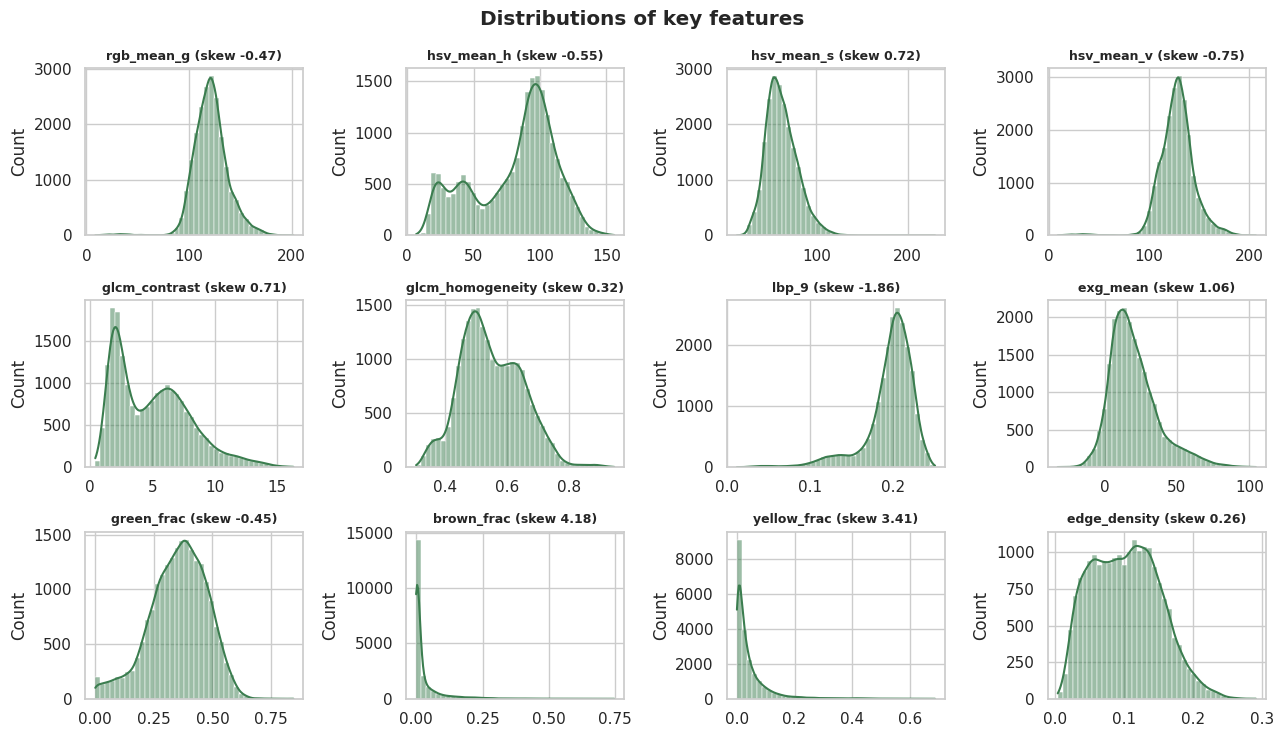

,skewness
vhist_7,13.50
lbp_8,9.90
vhist_0,8.12
hhist_4,6.94
shist_7,6.91
glcm_energy,5.80
brown_frac,4.18
lbp_7,-3.55


In [14]:
skew = X_df.skew().sort_values(key=np.abs, ascending=False)
pick = [f for f in ["rgb_mean_g", "hsv_mean_h", "hsv_mean_s", "hsv_mean_v", "glcm_contrast", "glcm_homogeneity",
                    "lbp_9", "exg_mean", "green_frac", "brown_frac", "yellow_frac", "edge_density"] if f in X_df]
fig, axes = plt.subplots(3, 4, figsize=(13, 7.5))
for ax, c in zip(axes.ravel(), pick):
    sns.histplot(X_df[c], kde=True, ax=ax, color="#3b7d4f", bins=40); ax.set_title(f"{c} (skew {X_df[c].skew():.2f})", fontsize=9); ax.set_xlabel("")
plt.suptitle("Distributions of key features", fontweight="bold"); plt.tight_layout(); savefig("distributions.png")
display(skew.head(8).round(2).rename("skewness").to_frame())
RES["eda"].update(n_skewed=int((skew.abs() > 1).sum()), skew_top=[{"feature": k, "skew": float(v)} for k, v in skew.head(6).items()])

**Finding:** several features (the lesion-colour fractions, edge density and some histogram bins) are strongly right-skewed with many near-zero values, because most leaf pixels are healthy green; colour means are closer to bell-shaped or multi-modal (one mode per plant species). Distribution-free models (trees/forests/boosting) handle this directly; standardisation is applied for the distance/gradient-based baselines.

## 7. Correlation analysis

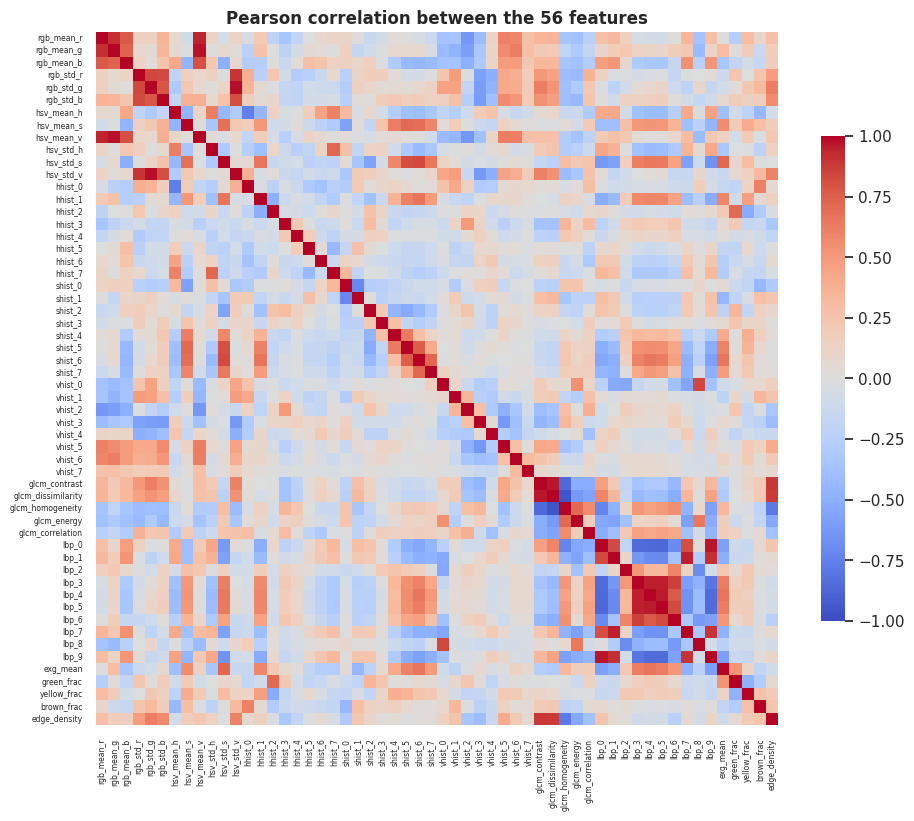

Feature pairs with |r| > 0.9: 13 of 1540


,a,b,r
220,rgb_std_g,hsv_std_v,0.977
61,rgb_mean_g,hsv_mean_v,0.969
1350,glcm_contrast,glcm_dissimilarity,0.968
1443,lbp_0,lbp_9,0.964
1369,glcm_dissimilarity,glcm_homogeneity,-0.959
1485,lbp_4,lbp_5,0.959
1475,lbp_3,lbp_5,0.951
1474,lbp_3,lbp_4,0.950
1454,lbp_1,lbp_7,0.945
7,rgb_mean_r,hsv_mean_v,0.942


In [15]:
corr = X_df.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True, cbar_kws={"shrink": .7})
ax.tick_params(labelsize=5.5); ax.set_title("Pearson correlation between the 56 features", fontweight="bold"); savefig("correlation_heatmap.png")
iu = np.triu_indices_from(corr, 1)
pairs = pd.DataFrame({"a": corr.columns[iu[0]], "b": corr.columns[iu[1]], "r": corr.values[iu]})
high = pairs[pairs.r.abs() > 0.9].sort_values("r", key=np.abs, ascending=False)
print(f"Feature pairs with |r| > 0.9: {len(high)} of {len(pairs)}"); display(high.head(10).round(3))
RES["eda"].update(n_pairs=int(len(pairs)), n_high_corr=int(len(high)),
                  high_corr=[{"a": r.a, "b": r.b, "r": float(r.r)} for r in high.head(6).itertuples()])

**Finding:** strongly correlated groups exist (e.g. RGB vs HSV means, neighbouring histogram bins, GLCM contrast vs dissimilarity), which is expected because they describe the same visual property in different ways. We **keep all features**: multicollinearity does not hurt tree ensembles, and Logistic Regression is L2-regularised by default. Feature importance in Week 2 shows which groups actually matter.

## 8. Feature encoding
* **Target:** categorical string labels → integers with `LabelEncoder` (needed by XGBoost and the ROC/AUC code).
* **Features:** all numeric, so **no one-hot encoding is needed**.
* **Scaling:** `StandardScaler` is placed *inside* a Pipeline for Logistic Regression and KNN, so it is fitted only on training folds — no leakage.

In [16]:
le = LabelEncoder().fit(df["label"]); y = le.transform(df["label"]); K = len(le.classes_)
CLASS_NAMES = [pretty(c) for c in le.classes_]
IS_HEALTHY = np.array(["healthy" in c.lower() for c in le.classes_])
PLANT_OF = np.array([split_name(c)[0] for c in le.classes_])
display(pd.DataFrame({"code": range(K), "class": CLASS_NAMES, "images": np.bincount(y)}))

,code,class,images
0,0,Pepper - Bacterial spot,997
1,1,Pepper - healthy,1478
2,2,Potato - Early blight,1000
3,3,Potato - Late blight,1000
4,4,Potato - healthy,152
5,5,Tomato - Bacterial spot,2127
6,6,Tomato - Early blight,1000
7,7,Tomato - Late blight,1909
8,8,Tomato - Leaf Mold,952
9,9,Tomato - Septoria leaf spot,1771


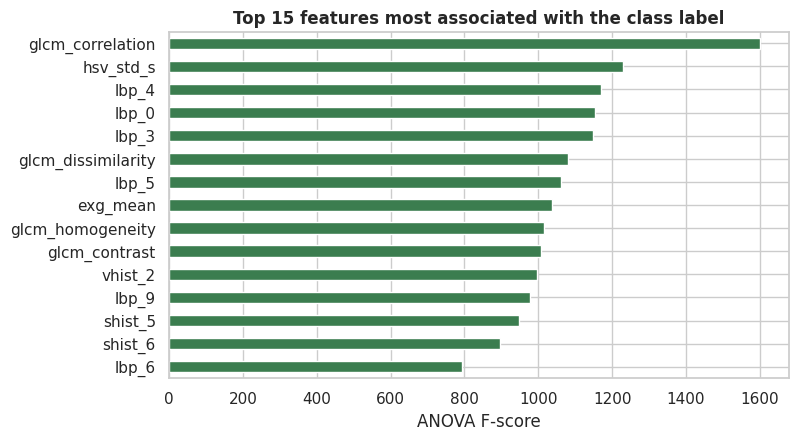

In [17]:
# feature-target relationship: ANOVA F-score of each feature against the class label
Fv, pv = f_classif(X_df.values, y)
fr = pd.Series(Fv, index=FEATURE_NAMES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5)); fr.head(15)[::-1].plot.barh(ax=ax, color="#3b7d4f")
ax.set_xlabel("ANOVA F-score"); ax.set_title("Top 15 features most associated with the class label"); savefig("feature_relevance.png")
RES["eda"]["top_f"] = [{"feature": k, "F": float(v)} for k, v in fr.head(6).items()]

## 9. Train / test split — 70 % / 30 %
Stratified on the class label so every disease appears in both sets in the same proportion (important with imbalanced classes).

In [18]:
X = X_df.values
Xtr, Xte, ytr, yte, itr, ite = train_test_split(X, y, np.arange(len(y)), test_size=0.30, stratify=y, random_state=SEED)
prop_gap = np.abs(np.bincount(ytr) / len(ytr) - np.bincount(yte) / len(yte)).max()
print(f"Train: {Xtr.shape} ({len(ytr)/len(y):.0%}) | Test: {Xte.shape} ({len(yte)/len(y):.0%}) | max class-share difference train vs test: {prop_gap:.4f}")
RES["split"] = dict(train=int(len(ytr)), test=int(len(yte)), max_prop_gap=float(prop_gap))

Train: (14446, 56) (70%) | Test: (6192, 56) (30%) | max class-share difference train vs test: 0.0001


# WEEK 1 (cont.) — Baseline Modelling
Three baseline classifiers with default settings, all trained on the 70 % split and evaluated on the untouched 30 % test set. **Metrics:** Accuracy, Precision, Recall, F1 (macro = every class counts equally, important with imbalance; weighted also shown) and the Confusion Matrix. We also report macro one-vs-rest AUC and the training accuracy (to spot overfitting).

In [19]:
def evaluate(name, model, fit=True):
    t0 = time.time()
    if fit: model.fit(Xtr, ytr)
    fit_s = time.time() - t0
    pred, proba = model.predict(Xte), model.predict_proba(Xte)
    row = dict(model=name, accuracy=accuracy_score(yte, pred),
               precision_macro=precision_score(yte, pred, average="macro", zero_division=0),
               recall_macro=recall_score(yte, pred, average="macro", zero_division=0),
               f1_macro=f1_score(yte, pred, average="macro", zero_division=0),
               f1_weighted=f1_score(yte, pred, average="weighted", zero_division=0),
               auc_macro=roc_auc_score(yte, proba, multi_class="ovr", average="macro"),
               train_acc=accuracy_score(ytr, model.predict(Xtr)), fit_s=fit_s)
    return row, pred, proba

FITTED, PRED, PROBA, ROWS = {}, {}, {}, []
def run(name, model, fit=True):
    row, pred, proba = evaluate(name, model, fit)
    FITTED[name], PRED[name], PROBA[name] = model, pred, proba; ROWS.append(row); return row

baselines = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=3000, random_state=SEED))]),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "KNN (k=5)": Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=5))]),
}
for n, m in baselines.items():
    print(n, {k: round(v, 3) for k, v in run(n, m).items() if k != "model"})
base_tbl = pd.DataFrame(ROWS).set_index("model")
display(base_tbl.round(4))
base_tbl.round(4).to_csv(OUT / "tables" / "baseline_models.csv")

Logistic Regression {'accuracy': 0.892, 'precision_macro': 0.882, 'recall_macro': 0.877, 'f1_macro': 0.878, 'f1_weighted': 0.891, 'auc_macro': np.float64(0.993), 'train_acc': 0.913, 'fit_s': 7.775}
Decision Tree {'accuracy': 0.787, 'precision_macro': 0.754, 'recall_macro': 0.751, 'f1_macro': 0.752, 'f1_weighted': 0.787, 'auc_macro': np.float64(0.868), 'train_acc': 1.0, 'fit_s': 2.453}
KNN (k=5) {'accuracy': 0.917, 'precision_macro': 0.905, 'recall_macro': 0.903, 'f1_macro': 0.903, 'f1_weighted': 0.916, 'auc_macro': np.float64(0.987), 'train_acc': 0.947, 'fit_s': 0.015}


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,auc_macro,train_acc,fit_s
model,,,,,,,,
Logistic Regression,0.8916,0.8822,0.8767,0.8783,0.8906,0.9930,0.9132,7.7747
Decision Tree,0.7871,0.7535,0.7507,0.7519,0.7870,0.8677,1.0000,2.4530
KNN (k=5),0.9168,0.9055,0.9027,0.9035,0.9163,0.9865,0.9473,0.0145


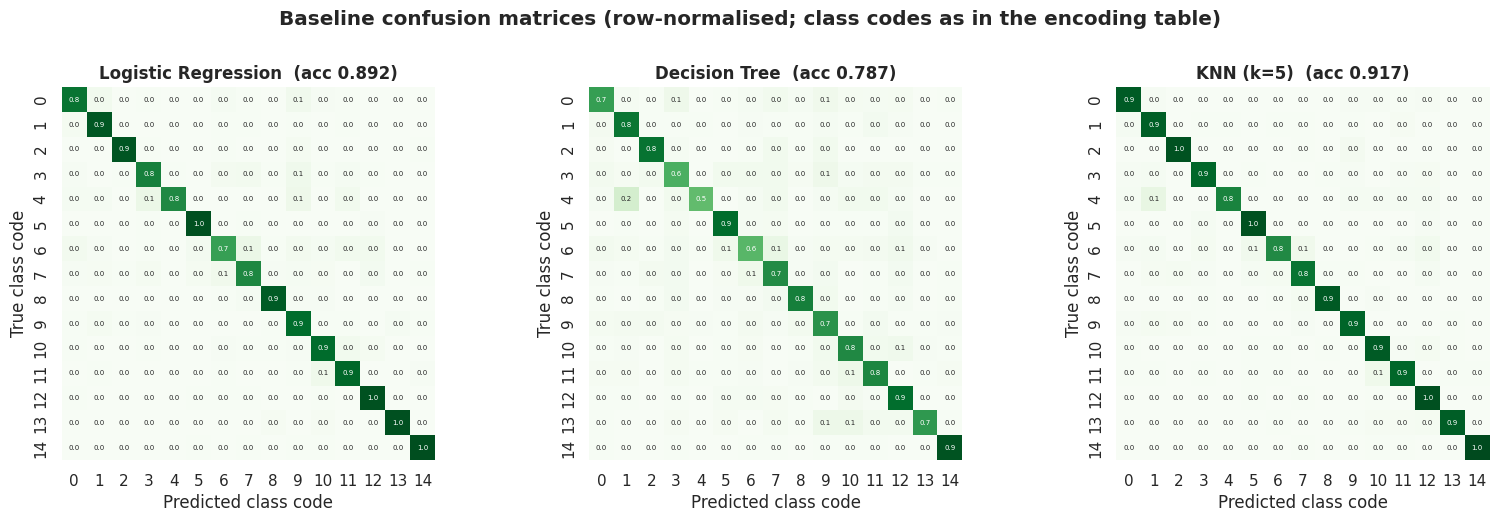

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, n in zip(axes, baselines):
    cm = confusion_matrix(yte, PRED[n], normalize="true")
    sns.heatmap(cm, ax=ax, cmap="Greens", vmin=0, vmax=1, cbar=False, square=True, xticklabels=range(K), yticklabels=range(K),
                annot=K <= 16, fmt=".1f" if K <= 16 else "", annot_kws={"size": 5})
    ax.set_title(f"{n}  (acc {accuracy_score(yte, PRED[n]):.3f})"); ax.set_xlabel("Predicted class code"); ax.set_ylabel("True class code")
plt.suptitle("Baseline confusion matrices (row-normalised; class codes as in the encoding table)", y=1.02, fontweight="bold")
plt.tight_layout(); savefig("baseline_confusion.png")

In [21]:
# ---- interpretation paragraph (generated from the actual numbers) ----
b = base_tbl.sort_values("f1_macro", ascending=False)
best, worst = b.iloc[0], b.iloc[-1]
gap = (base_tbl.train_acc - base_tbl.accuracy)
lin, others = base_tbl.loc["Logistic Regression", "f1_macro"], base_tbl.drop("Logistic Regression").f1_macro.max()
t = (f"{b.index[0]} was the strongest baseline (accuracy {best.accuracy:.3f}, macro-F1 {best.f1_macro:.3f}, macro-AUC {best.auc_macro:.3f}), "
     f"while {b.index[-1]} was the weakest (macro-F1 {worst.f1_macro:.3f}). ")
t += ("The linear model trails the best non-linear learner, which suggests the classes are not linearly separable in colour/texture space. "
      if lin < others - 0.01 else "The linear model is competitive with the non-linear learners, so a large part of the class structure is linear in these features. ")
mg = gap.idxmax()
t += (f"{mg} shows the largest train-test accuracy gap ({gap.max():.3f}), a sign of overfitting. " if gap.max() > 0.05
      else "Train and test accuracy are close for every baseline, so overfitting is not a concern at this stage. ")
t += (f"Macro-F1 is {'lower' if best.f1_macro < best.accuracy else 'similar'} compared with accuracy, which shows that rarer classes "
      f"are {'harder' if best.f1_macro < best.accuracy - 0.01 else 'not noticeably harder'} to classify — the motivation for the imbalance study in Week 2.")
RES["baseline"] = base_tbl.reset_index().to_dict("records"); RES["text"]["baseline"] = t
display(Markdown("**Interpretation.** " + t))

**Interpretation.** KNN (k=5) was the strongest baseline (accuracy 0.917, macro-F1 0.903, macro-AUC 0.987), while Decision Tree was the weakest (macro-F1 0.752). The linear model trails the best non-linear learner, which suggests the classes are not linearly separable in colour/texture space. Decision Tree shows the largest train-test accuracy gap (0.213), a sign of overfitting. Macro-F1 is lower compared with accuracy, which shows that rarer classes are harder to classify — the motivation for the imbalance study in Week 2.

# WEEK 2 — Advanced Modelling & Optimisation
## 10. Class imbalance: class weights vs SMOTE
The largest class is many times bigger than the smallest. We compare three treatments on a Random Forest (200 trees): **none**, **`class_weight="balanced"`** and **SMOTE** (synthetic minority over-sampling, applied *inside* the pipeline so it only touches training folds). The winner (by macro-F1) is used for the tuned models.

,accuracy,f1_macro,recall_macro,minority_recall
strategy,,,,
None,0.9283,0.9052,0.8936,0.4783
Class weights,0.9288,0.9083,0.8962,0.5217
SMOTE,0.9364,0.9279,0.9283,0.8478


Smallest training class: 'Potato - healthy'. Chosen strategy (best macro-F1): SMOTE


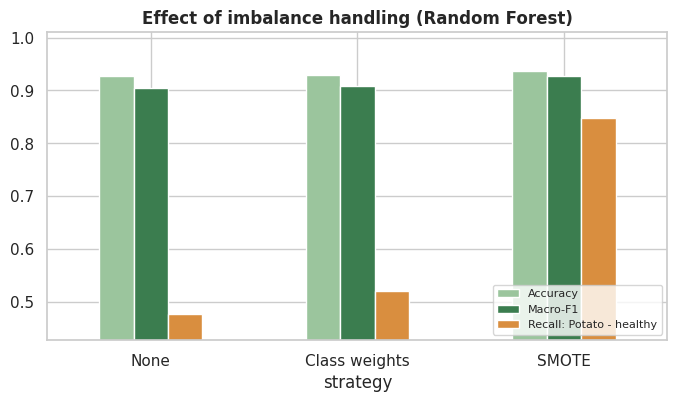

**Interpretation.** Imbalance handling changed the result: macro-F1 was 0.905 with no treatment, 0.908 with class weights and 0.928 with SMOTE. Recall on the rarest class ('Potato - healthy') was 0.478 / 0.522 / 0.848 respectively. 'SMOTE' gave the best macro-F1 and is used for the tuned models.

In [22]:
minor = int(np.bincount(ytr).argmin())
imb_cfg = {
    "None": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    "Class weights": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "SMOTE": ImbPipeline([("smote", SMOTE(random_state=SEED)), ("rf", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))]),
}
imb_rows = []
for n, m in imb_cfg.items():
    m.fit(Xtr, ytr); p = m.predict(Xte)
    imb_rows.append(dict(strategy=n, accuracy=accuracy_score(yte, p), f1_macro=f1_score(yte, p, average="macro"),
                         recall_macro=recall_score(yte, p, average="macro"),
                         minority_recall=recall_score(yte, p, labels=[minor], average=None)[0]))
imb = pd.DataFrame(imb_rows).set_index("strategy"); display(imb.round(4)); imb.round(4).to_csv(OUT / "tables" / "imbalance_strategies.csv")
STRAT = imb.f1_macro.idxmax()
print(f"Smallest training class: '{CLASS_NAMES[minor]}'. Chosen strategy (best macro-F1): {STRAT}")

fig, ax = plt.subplots(figsize=(8, 4)); imb[["accuracy", "f1_macro", "minority_recall"]].plot.bar(ax=ax, rot=0, color=["#9bc59d", "#3b7d4f", "#d98e3f"])
ax.set_ylim(max(0, imb[["accuracy", "f1_macro", "minority_recall"]].min().min() - 0.05), 1.01)
ax.set_title("Effect of imbalance handling (Random Forest)"); ax.legend(["Accuracy", "Macro-F1", f"Recall: {CLASS_NAMES[minor]}"], loc="lower right", fontsize=8)
savefig("imbalance_comparison.png")
d_f1 = imb.f1_macro.max() - imb.loc["None", "f1_macro"]
t = (f"Imbalance handling {'changed' if abs(d_f1) > 0.002 else 'barely changed'} the result: macro-F1 was {imb.loc['None','f1_macro']:.3f} with no treatment, "
     f"{imb.loc['Class weights','f1_macro']:.3f} with class weights and {imb.loc['SMOTE','f1_macro']:.3f} with SMOTE. "
     f"Recall on the rarest class ('{CLASS_NAMES[minor]}') was {imb.loc['None','minority_recall']:.3f} / {imb.loc['Class weights','minority_recall']:.3f} / {imb.loc['SMOTE','minority_recall']:.3f} respectively. "
     + (f"'{STRAT}' gave the best macro-F1 and is used for the tuned models." if STRAT != "None" else
        "Because no treatment improved macro-F1, the tuned models use the untreated data; the features separate the classes well enough that imbalance is not the bottleneck."))
RES["imbalance"] = imb.reset_index().to_dict("records"); RES["imbalance_choice"] = STRAT; RES["text"]["imbalance"] = t
RES["minority_class"] = CLASS_NAMES[minor]; display(Markdown("**Interpretation.** " + t))

## 11. Random Forest and XGBoost with GridSearchCV
Both ensembles are tuned with `GridSearchCV` (3-fold stratified CV on the **training set only**, scoring = macro-F1). The imbalance strategy chosen above is applied inside the search. Default (untuned) XGBoost is also evaluated so the benefit of tuning is visible.

In [23]:
from plant_features import BalancedXGB   # XGBoost + balanced sample weights (defined in plant_features.py so the model can be pickled)

def make_est(name, strat):
    if name == "Random Forest":
        base = RandomForestClassifier(random_state=SEED, n_jobs=-1, class_weight="balanced" if strat == "Class weights" else None)
        grid = {"n_estimators": [200, 400], "max_depth": [None, 20], "min_samples_leaf": [1, 2]}
    else:
        cls = BalancedXGB if strat == "Class weights" else XGBClassifier
        base = cls(tree_method="hist", eval_metric="mlogloss", random_state=SEED, n_jobs=-1, verbosity=0)
        grid = {"n_estimators": [150, 300], "max_depth": [4, 6], "learning_rate": [0.1]}
    if strat == "SMOTE":
        return ImbPipeline([("smote", SMOTE(random_state=SEED)), ("model", base)]), {f"model__{k}": v for k, v in grid.items()}
    return base, grid

# default (untuned) XGBoost + default Random Forest for reference
run("Random Forest (default)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))
run("XGBoost (default)", XGBClassifier(n_estimators=200, tree_method="hist", eval_metric="mlogloss", random_state=SEED, n_jobs=-1, verbosity=0))

cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
TUNED, tune_rows = {}, []
for name in ["Random Forest", "XGBoost"]:
    est, grid = make_est(name, STRAT)
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=cv3, scoring="f1_macro", n_jobs=1, refit=True, verbose=1).fit(Xtr, ytr)
    print(f"{name}: best CV macro-F1 {gs.best_score_:.4f} | params {gs.best_params_} | {time.time()-t0:.0f}s")
    TUNED[name] = gs
    pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").to_csv(OUT / "tables" / f"gridsearch_{name.replace(' ', '_').lower()}.csv", index=False)
    row = run(f"{name} (tuned)", gs.best_estimator_, fit=False)
    tune_rows.append(dict(model=name, best_params={k.replace("model__", ""): v for k, v in gs.best_params_.items()},
                          grid_size=int(np.prod([len(v) for v in grid.values()])), cv_best_f1=float(gs.best_score_)))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Random Forest: best CV macro-F1 0.9100 | params {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200} | 894s
Fitting 3 folds for each of 4 candidates, totalling 12 fits
XGBoost: best CV macro-F1 0.9340 | params {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 300} | 316s


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,auc_macro,train_acc,fit_s
model,,,,,,,,
Logistic Regression,0.8916,0.8822,0.8767,0.8783,0.8906,0.9930,0.9132,7.7747
Decision Tree,0.7871,0.7535,0.7507,0.7519,0.7870,0.8677,1.0000,2.4530
KNN (k=5),0.9168,0.9055,0.9027,0.9035,0.9163,0.9865,0.9473,0.0145
Random Forest (default),0.9283,0.9307,0.8936,0.9052,0.9270,0.9971,1.0000,13.7466
XGBoost (default),0.9517,0.9460,0.9368,0.9411,0.9515,0.9986,1.0000,14.8034
Random Forest (tuned),0.9364,0.9279,0.9283,0.9279,0.9362,0.9977,1.0000,0.0000
XGBoost (tuned),0.9522,0.9460,0.9463,0.9461,0.9522,0.9987,1.0000,0.0000


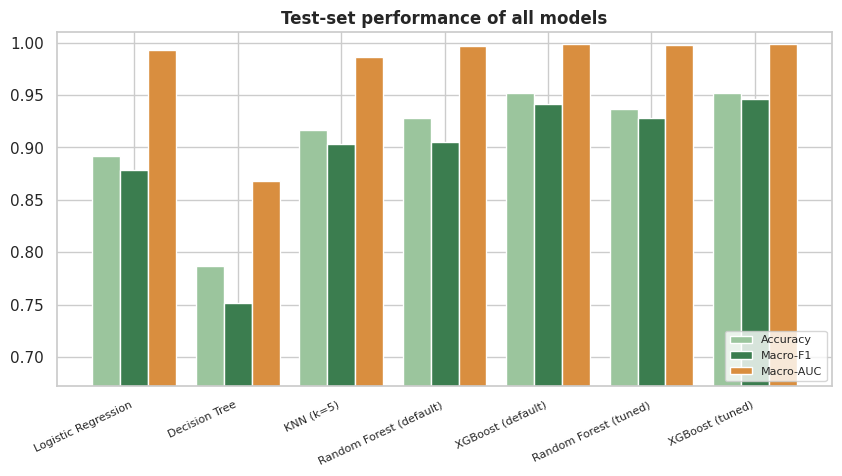

In [24]:
all_tbl = pd.DataFrame(ROWS).set_index("model"); display(all_tbl.round(4)); all_tbl.round(4).to_csv(OUT / "tables" / "all_models_test.csv")
tbl = all_tbl.copy()
fig, ax = plt.subplots(figsize=(10, 4.6)); x = np.arange(len(tbl)); w = .27
ax.bar(x - w, tbl.accuracy, w, label="Accuracy", color="#9bc59d"); ax.bar(x, tbl.f1_macro, w, label="Macro-F1", color="#3b7d4f"); ax.bar(x + w, tbl.auc_macro, w, label="Macro-AUC", color="#d98e3f")
ax.set_xticks(x); ax.set_xticklabels(tbl.index, rotation=25, ha="right", fontsize=8); ax.set_ylim(max(0, tbl[["accuracy", "f1_macro"]].min().min() - 0.08), 1.01)
ax.legend(loc="lower right", fontsize=8); ax.set_title("Test-set performance of all models"); savefig("model_comparison.png")
RES["all_models"] = all_tbl.reset_index().to_dict("records"); RES["tuning"] = tune_rows
for r in RES["tuning"]:
    d = all_tbl.loc[f"{r['model']} (tuned)"]; r.update({k: float(d[k]) for k in ["accuracy", "f1_macro", "auc_macro"]})
RES["xgb_default_f1"] = float(all_tbl.loc["XGBoost (default)", "f1_macro"]); RES["rf_default_f1"] = float(all_tbl.loc["Random Forest (default)", "f1_macro"])

## 12. Cross-validation (5-fold, stratified, training set)
CV gives a more stable estimate than the single test split and is used to **choose the final model** (so the test set stays untouched for the final report). SMOTE/scaling are inside the pipelines, so they are re-fitted in every fold.

Logistic Regression: macro-F1 0.8897 ± 0.0119 (34s)
Decision Tree: macro-F1 0.7330 ± 0.0127 (9s)
KNN (k=5): macro-F1 0.8951 ± 0.0141 (1s)
Random Forest (tuned): macro-F1 0.9191 ± 0.0100 (150s)
XGBoost (tuned): macro-F1 0.9378 ± 0.0151 (148s)


,acc_mean,acc_std,f1_mean,f1_std
model,,,,
Logistic Regression,0.9004,0.0091,0.8897,0.0119
Decision Tree,0.7709,0.0082,0.7330,0.0127
KNN (k=5),0.9113,0.0100,0.8951,0.0141
Random Forest (tuned),0.9329,0.0081,0.9191,0.0100
XGBoost (tuned),0.9506,0.0076,0.9378,0.0151


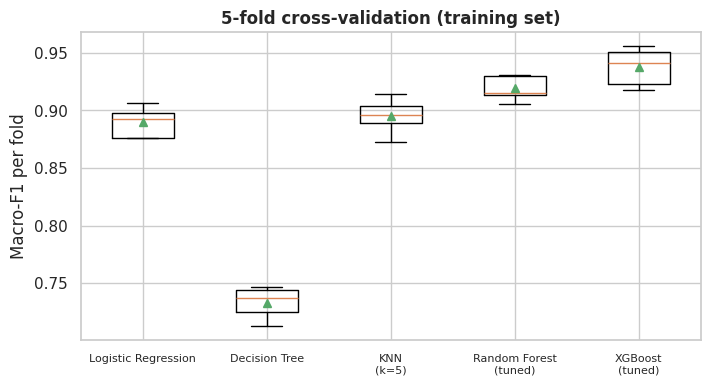

Final model (highest mean CV macro-F1): XGBoost (tuned)


In [25]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
cand = {"Logistic Regression": FITTED["Logistic Regression"], "Decision Tree": FITTED["Decision Tree"], "KNN (k=5)": FITTED["KNN (k=5)"],
        "Random Forest (tuned)": FITTED["Random Forest (tuned)"], "XGBoost (tuned)": FITTED["XGBoost (tuned)"]}
from sklearn.base import clone
cv_rows, cv_raw = [], {}
for n, m in cand.items():
    t0 = time.time()
    r = cross_validate(clone(m), Xtr, ytr, cv=cv5, scoring={"acc": "accuracy", "f1": "f1_macro"}, n_jobs=1)
    cv_raw[n] = r["test_f1"]
    cv_rows.append(dict(model=n, acc_mean=r["test_acc"].mean(), acc_std=r["test_acc"].std(), f1_mean=r["test_f1"].mean(), f1_std=r["test_f1"].std()))
    print(f"{n}: macro-F1 {r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f} ({time.time()-t0:.0f}s)")
cv_tbl = pd.DataFrame(cv_rows).set_index("model"); display(cv_tbl.round(4)); cv_tbl.round(4).to_csv(OUT / "tables" / "cross_validation.csv")
fig, ax = plt.subplots(figsize=(8, 4)); ax.boxplot(list(cv_raw.values()), showmeans=True); ax.set_xticklabels([k.replace(" (", "\n(") for k in cv_raw], fontsize=8)
ax.set_ylabel("Macro-F1 per fold"); ax.set_title("5-fold cross-validation (training set)"); savefig("cv_boxplot.png")
RES["cv"] = cv_tbl.reset_index().to_dict("records")
FINAL = cv_tbl.f1_mean.idxmax(); print("Final model (highest mean CV macro-F1):", FINAL)

## 13. ROC curves and AUC (one-vs-rest)
For the multi-class problem each class is scored against all others; we show every class curve plus the **micro** and **macro** averages for the selected final model.

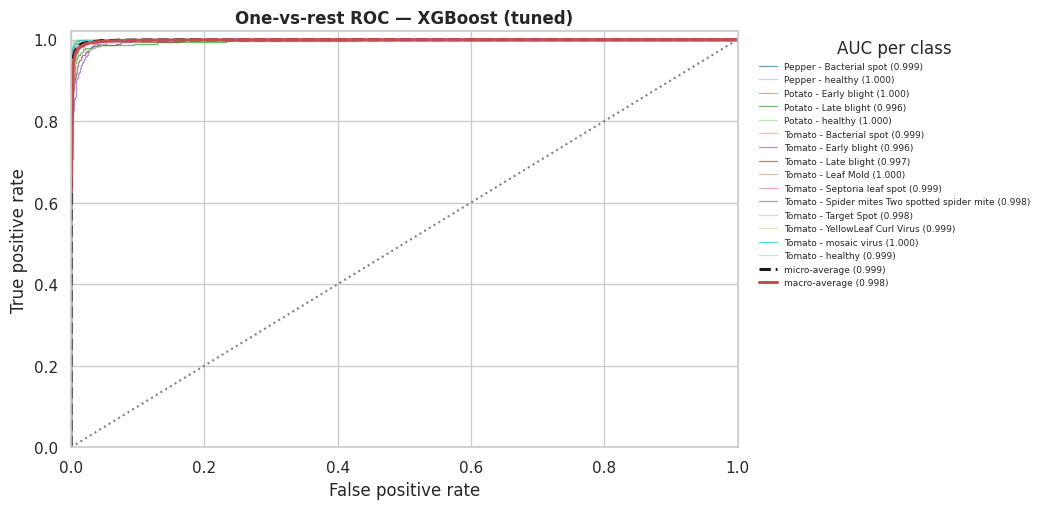

Macro OvR AUC = 0.9987 | micro-average AUC = 0.9989


In [26]:
final_model, fpred, fproba = FITTED[FINAL], PRED[FINAL], PROBA[FINAL]
Yb = label_binarize(yte, classes=range(K))
fpr, tpr, roc_auc = {}, {}, {}
for k in range(K):
    fpr[k], tpr[k], _ = roc_curve(Yb[:, k], fproba[:, k]); roc_auc[k] = auc(fpr[k], tpr[k])
fpr["micro"], tpr["micro"], _ = roc_curve(Yb.ravel(), fproba.ravel()); roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
grid_f = np.linspace(0, 1, 300); mean_tpr = np.mean([np.interp(grid_f, fpr[k], tpr[k]) for k in range(K)], axis=0)
roc_auc["macro"] = auc(grid_f, mean_tpr)
fig, ax = plt.subplots(figsize=(8.6, 5.4)); cmap = plt.cm.tab20(np.linspace(0, 1, K))
for k in range(K): ax.plot(fpr[k], tpr[k], lw=.9, alpha=.7, color=cmap[k], label=f"{CLASS_NAMES[k]} ({roc_auc[k]:.3f})")
ax.plot(fpr["micro"], tpr["micro"], "k--", lw=2.2, label=f"micro-average ({roc_auc['micro']:.3f})"); ax.plot(grid_f, mean_tpr, "r-", lw=2.2, label=f"macro-average ({roc_auc['macro']:.3f})")
ax.plot([0, 1], [0, 1], ":", color="grey"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"One-vs-rest ROC — {FINAL}"); ax.legend(fontsize=6.5, loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False, title="AUC per class"); savefig("roc_final.png")
auc_ovr = roc_auc_score(yte, fproba, multi_class="ovr", average="macro")
print(f"Macro OvR AUC = {auc_ovr:.4f} | micro-average AUC = {roc_auc['micro']:.4f}")

# WEEK 4 — Interpretation, Documentation & Deployment Insight
## 14. Final model: selection and detailed evaluation

,class,precision,recall,f1,support,auc
6,Tomato - Early blight,0.883,0.877,0.880,300,0.996
4,Potato - healthy,0.891,0.891,0.891,46,1.000
3,Potato - Late blight,0.913,0.910,0.912,300,0.996
7,Tomato - Late blight,0.937,0.913,0.925,573,0.997
11,Tomato - Target Spot,0.925,0.941,0.933,421,0.998
0,Pepper - Bacterial spot,0.934,0.953,0.944,299,0.999
10,Tomato - Spider mites Two spotted spider mite,0.934,0.956,0.945,503,0.998
9,Tomato - Septoria leaf spot,0.964,0.953,0.958,531,0.999
5,Tomato - Bacterial spot,0.958,0.962,0.960,638,0.999
2,Potato - Early blight,0.957,0.973,0.965,300,1.000


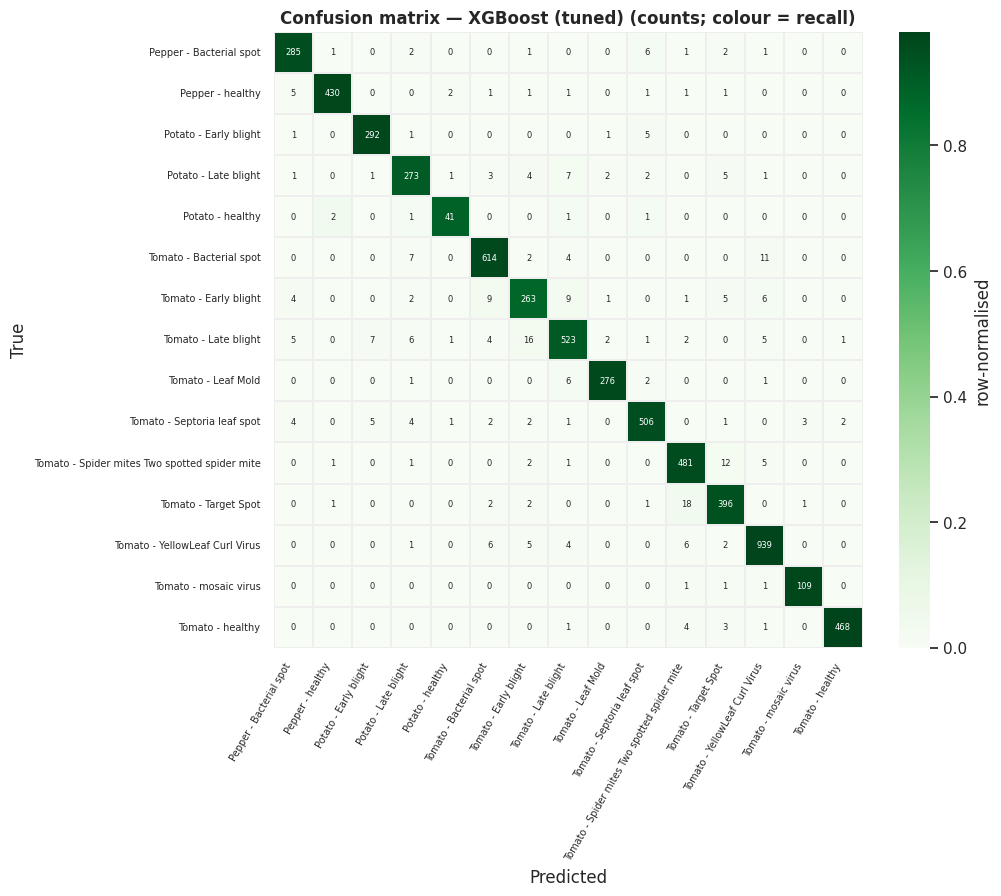

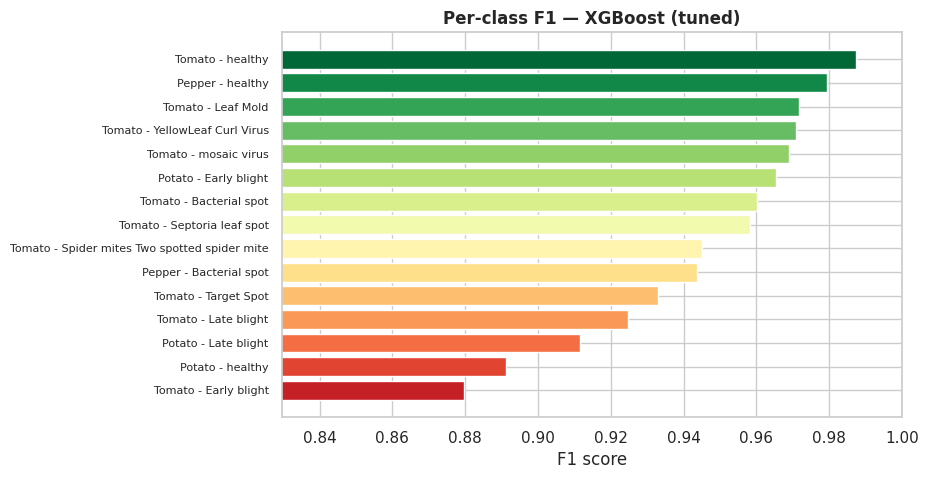

Most frequent confusions:
  {'true': 'Tomato - Target Spot', 'pred': 'Tomato - Spider mites Two spotted spider mite', 'n': 18}
  {'true': 'Tomato - Late blight', 'pred': 'Tomato - Early blight', 'n': 16}
  {'true': 'Tomato - Spider mites Two spotted spider mite', 'pred': 'Tomato - Target Spot', 'n': 12}
  {'true': 'Tomato - Bacterial spot', 'pred': 'Tomato - YellowLeaf Curl Virus', 'n': 11}
  {'true': 'Tomato - Early blight', 'pred': 'Tomato - Bacterial spot', 'n': 9}
Diseased leaf predicted as healthy: 0.17% | healthy leaf flagged as diseased: 2.38% | correct plant species: 98.26%


In [27]:
rep = classification_report(yte, fpred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
per_class = pd.DataFrame([{"class": c, "precision": rep[c]["precision"], "recall": rep[c]["recall"], "f1": rep[c]["f1-score"],
                           "support": int(rep[c]["support"]), "auc": roc_auc[i]} for i, c in enumerate(CLASS_NAMES)]).sort_values("f1")
display(per_class.round(3)); per_class.round(4).to_csv(OUT / "tables" / "final_per_class.csv", index=False)

cm = confusion_matrix(yte, fpred); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(9.5, 8)); sns.heatmap(cmn, annot=cm, fmt="d", cmap="Greens", ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            annot_kws={"size": 6}, cbar_kws={"label": "row-normalised"}, linewidths=.3, linecolor="#eee")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Confusion matrix — {FINAL} (counts; colour = recall)")
plt.xticks(rotation=60, ha="right", fontsize=7); plt.yticks(fontsize=7); savefig("confusion_final.png")

fig, ax = plt.subplots(figsize=(8, 5)); ps = per_class.sort_values("f1")
ax.barh(ps["class"], ps["f1"], color=plt.cm.RdYlGn(ps["f1"].rank(pct=True))); ax.set_xlabel("F1 score"); ax.set_xlim(max(0, ps.f1.min() - .05), 1.0)
ax.set_title(f"Per-class F1 — {FINAL}"); ax.tick_params(axis="y", labelsize=8); savefig("per_class_f1.png")

off = cm.copy(); np.fill_diagonal(off, 0)
top_conf = [dict(true=CLASS_NAMES[i], pred=CLASS_NAMES[j], n=int(off[i, j])) for i, j in zip(*np.unravel_index(np.argsort(-off, axis=None)[:5], off.shape)) if off[i, j] > 0]
print("Most frequent confusions:", *top_conf, sep="\n  ")

# error type that matters most in the field
dis_true = ~IS_HEALTHY[yte]; dis_as_healthy = float((IS_HEALTHY[fpred] & dis_true).sum() / max(1, dis_true.sum()))
healthy_as_dis = float(((~IS_HEALTHY[fpred]) & IS_HEALTHY[yte]).sum() / max(1, IS_HEALTHY[yte].sum()))
plant_acc = float((PLANT_OF[fpred] == PLANT_OF[yte]).mean())
print(f"Diseased leaf predicted as healthy: {dis_as_healthy:.2%} | healthy leaf flagged as diseased: {healthy_as_dis:.2%} | correct plant species: {plant_acc:.2%}")

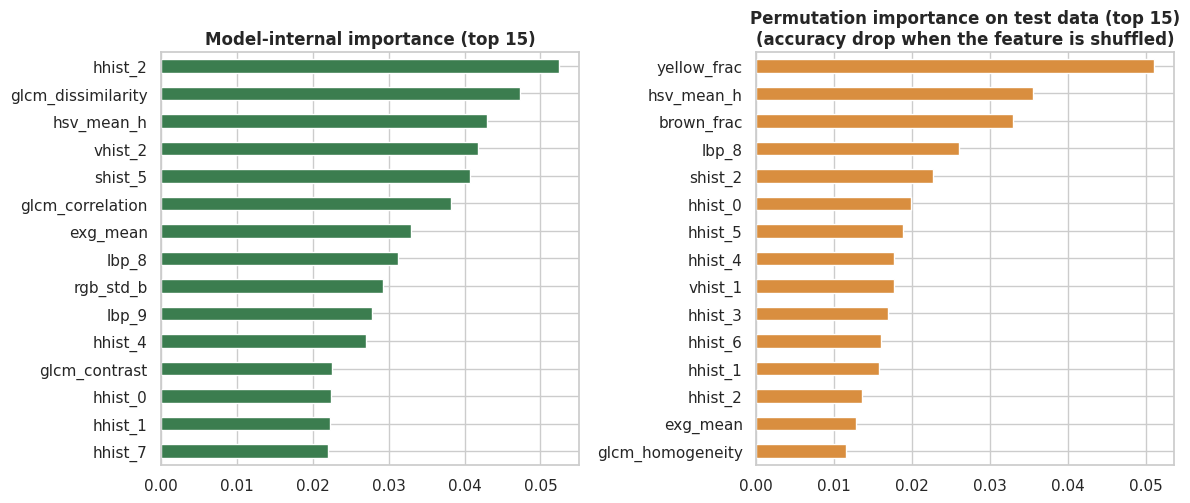

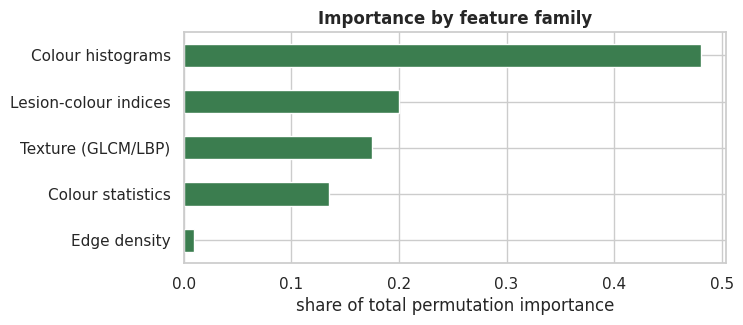

,perm. importance
yellow_frac,0.0511
hsv_mean_h,0.0355
brown_frac,0.0330
lbp_8,0.0261
shist_2,0.0227
hhist_0,0.0199
hhist_5,0.0189
hhist_4,0.0177


,% share
Colour histograms,48.0
Lesion-colour indices,20.0
Texture (GLCM/LBP),17.5
Colour statistics,13.5
Edge density,1.0


In [28]:
# ---- feature importance: model-internal + permutation (model-agnostic, on test data) ----
est = final_model
while hasattr(est, "steps"): est = est.steps[-1][1]
internal = (est.feature_importances_ if hasattr(est, "feature_importances_") else
            np.abs(est.coef_).mean(0) if hasattr(est, "coef_") else None)
rs = np.random.RandomState(SEED); sub = rs.choice(len(yte), min(2000, len(yte)), replace=False)
pi = permutation_importance(final_model, Xte[sub], yte[sub], n_repeats=5, random_state=SEED, scoring="accuracy", n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=FEATURE_NAMES).clip(lower=0)
fig, axes = plt.subplots(1, 2 if internal is not None else 1, figsize=(12 if internal is not None else 6, 5.2)); axes = np.atleast_1d(axes)
if internal is not None:
    s = pd.Series(internal, index=FEATURE_NAMES).sort_values(ascending=False).head(15)[::-1]; s.plot.barh(ax=axes[0], color="#3b7d4f"); axes[0].set_title("Model-internal importance (top 15)")
perm.sort_values(ascending=False).head(15)[::-1].plot.barh(ax=axes[-1], color="#d98e3f"); axes[-1].set_title("Permutation importance on test data (top 15)\n(accuracy drop when the feature is shuffled)")
plt.tight_layout(); savefig("feature_importance.png")
grp = perm.groupby(pd.Series(FAMILY)).sum(); grp = (grp / grp.sum()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3)); grp[::-1].plot.barh(ax=ax, color="#3b7d4f"); ax.set_xlabel("share of total permutation importance"); ax.set_title("Importance by feature family"); savefig("importance_groups.png")
top_feats = perm.sort_values(ascending=False).head(8)
display(top_feats.round(4).rename("perm. importance").to_frame()); display((grp * 100).round(1).rename("% share").to_frame())

In [29]:
# ---- deployment-relevant numbers: inference speed ----
smp = meta.path.sample(min(40, len(meta)), random_state=SEED).tolist(); t0 = time.time()
fv = np.vstack([extract_features(np.asarray(Image.open(p).convert("RGB"))) for p in smp]); t_feat = (time.time() - t0) / len(smp) * 1000
t0 = time.time(); [final_model.predict(fv[i:i+1]) for i in range(len(fv))]; t_pred = (time.time() - t0) / len(fv) * 1000
print(f"Feature extraction {t_feat:.1f} ms/image + prediction {t_pred:.1f} ms/image")

fm = all_tbl.loc[FINAL] if FINAL in all_tbl.index else None
fin_metrics = dict(accuracy=accuracy_score(yte, fpred), precision_macro=precision_score(yte, fpred, average="macro"), recall_macro=recall_score(yte, fpred, average="macro"),
                   f1_macro=f1_score(yte, fpred, average="macro"), f1_weighted=f1_score(yte, fpred, average="weighted"), auc_macro=auc_ovr, auc_micro=roc_auc["micro"])
worst3 = per_class.head(3)
RES["final"] = dict(model=FINAL, rule="highest mean 5-fold CV macro-F1 on the training set", metrics={k: float(v) for k, v in fin_metrics.items()},
    per_class=per_class.to_dict("records"), top_conf=top_conf, dis_as_healthy=dis_as_healthy, healthy_as_dis=healthy_as_dis, plant_acc=plant_acc,
    perm_top=[{"feature": k, "imp": float(v)} for k, v in top_feats.items()], family_share={k: float(v) for k, v in grp.items()},
    ms_feature=float(t_feat), ms_predict=float(t_pred), worst=[{"class": r["class"], "f1": float(r["f1"])} for r in worst3.to_dict("records")])

Feature extraction 14.6 ms/image + prediction 2.1 ms/image


In [30]:
# ---- written conclusions generated from the results above ----
m = fin_metrics; cvr = cv_tbl.loc[FINAL]; runner = cv_tbl.drop(FINAL).f1_mean.idxmax()
sel = (f"**{FINAL}** was selected because it achieved the highest mean 5-fold cross-validated macro-F1 on the training data "
       f"({cvr.f1_mean:.3f} ± {cvr.f1_std:.3f}); the runner-up was {runner} ({cv_tbl.loc[runner,'f1_mean']:.3f}). Choosing by cross-validation rather than by the test score keeps the test set an unbiased final check. "
       f"On the held-out test set it reaches accuracy {m['accuracy']:.3f}, macro-precision {m['precision_macro']:.3f}, macro-recall {m['recall_macro']:.3f}, macro-F1 {m['f1_macro']:.3f} and macro one-vs-rest AUC {m['auc_macro']:.3f}. "
       f"The train-test accuracy gap is {all_tbl.loc[FINAL].train_acc - m['accuracy']:.3f}" if FINAL in all_tbl.index else "")
tuned_gain = ""
if f"{FINAL}" .startswith(("Random Forest", "XGBoost")):
    nm = FINAL.replace(" (tuned)", ""); dflt = RES["rf_default_f1"] if nm == "Random Forest" else RES["xgb_default_f1"]
    tuned_gain = (f" Hyper-parameter tuning improved test macro-F1 from {dflt:.3f} (default) to {m['f1_macro']:.3f}." if m['f1_macro'] > dflt + 0.0005 else
                  f" Hyper-parameter tuning did not improve test macro-F1 ({dflt:.3f} default vs {m['f1_macro']:.3f} tuned), i.e. the default settings were already near-optimal for these features; tuning mainly improved cross-validated stability.")
sel = sel + "." + tuned_gain
fi = (f"The most influential features are {', '.join(top_feats.index[:4])}. By family, {grp.index[0]} carries {grp.iloc[0]*100:.0f}% of the permutation importance, "
      f"followed by {grp.index[1]} ({grp.iloc[1]*100:.0f}%)" + (f" and {grp.index[2]} ({grp.iloc[2]*100:.0f}%)." if len(grp) > 2 else ".") +
      (" This matches plant-pathology intuition: diseases mainly change leaf colour (yellowing, browning, necrotic spots)." if grp.index[0] != "Texture (GLCM/LBP)"
       else " Texture features dominate, i.e. the fine surface pattern of lesions separates the classes better than overall colour."))
biz = [
    f"**Triage-level accuracy at very low cost.** The model labels {m['accuracy']:.1%} of unseen leaf photos correctly (macro-F1 {m['f1_macro']:.3f}) and identifies the right crop species {plant_acc:.1%} of the time, using only simple colour/texture statistics — no GPU required.",
    f"**Fast enough for the field.** Feature extraction takes about {t_feat:.0f} ms and prediction {t_pred:.1f} ms per image on CPU, so the system can run offline on a laptop or low-end phone backend where connectivity is poor.",
    f"**The costly error is a missed disease.** {dis_as_healthy:.1%} of diseased test leaves were predicted as healthy (a delayed treatment risk), while {healthy_as_dis:.1%} of healthy leaves were flagged as diseased (an unnecessary inspection). A deployment should route low-confidence predictions to an expert.",
    f"**Where to collect more data / get human review:** the weakest classes are " + ", ".join(f"{r['class']} (F1 {r['f1']:.2f})" for r in worst3.to_dict('records')) + ".",
    (f"**Colour drives the diagnosis.** {grp.index[0]} features dominate, so consistent lighting and a plain background during photo capture matter."
     if grp.index[0] != "Texture (GLCM/LBP)" else f"**Texture drives the diagnosis.** {grp.index[0]} features dominate, so sharp, in-focus close-ups of the leaf surface matter."),
]
lim = [
    "**Controlled imagery.** PlantVillage photos are single leaves on a plain background under uniform light. Accuracy on real field photos (clutter, shadows, several leaves) is expected to be lower — a domain-shift risk we did not measure.",
    "**Possible near-duplicate leakage.** The dataset contains several photos/augmentations of the same physical leaf; a random 70/30 split can put near-identical images in both sets, which can make test scores optimistic. A leaf-level (grouped) split is not directly possible because leaf identifiers are not provided.",
    "**Hand-crafted features.** 56 global colour/texture statistics cannot capture local lesion shape or spatial layout" +
    (f"; the most frequent confusion on the test set was '{top_conf[0]['true']}' predicted as '{top_conf[0]['pred']}' ({top_conf[0]['n']} images)." if top_conf else "."),
    "**Limited scope.** Only 3 crops and 15 classes; a new disease or crop requires re-training. The model always outputs one of the known classes (no 'unknown' option).",
    "**Imbalance.** Rare classes have far fewer images; their metrics are estimated from small test counts and are noisier.",
]
fut = [
    "Fine-tune a CNN / Vision Transformer (e.g. MobileNetV3, EfficientNet) with transfer learning and augmentation, and compare it against this classical baseline.",
    "Evaluate on real field images (e.g. PlantDoc) and add background segmentation and a leaf detector; use grouped/leaf-level splits to remove leakage.",
    "Add probability calibration and an 'uncertain / consult an expert' threshold; add Grad-CAM-style explanations for farmers.",
    "Add more crops and severity estimation (regression of % leaf area affected); package as an offline mobile app with local-language advice.",
]
RES["text"].update(selection=sel, feature_importance=fi, business=biz, limitations=lim, future=fut)
display(Markdown("### Final model selection\n" + sel + "\n\n### Feature importance explanation\n" + fi + "\n\n### Business insights\n" + "\n".join("- " + b for b in biz)))

### Final model selection
**XGBoost (tuned)** was selected because it achieved the highest mean 5-fold cross-validated macro-F1 on the training data (0.938 ± 0.015); the runner-up was Random Forest (tuned) (0.919). Choosing by cross-validation rather than by the test score keeps the test set an unbiased final check. On the held-out test set it reaches accuracy 0.952, macro-precision 0.946, macro-recall 0.946, macro-F1 0.946 and macro one-vs-rest AUC 0.999. The train-test accuracy gap is 0.048. Hyper-parameter tuning improved test macro-F1 from 0.941 (default) to 0.946.

### Feature importance explanation
The most influential features are yellow_frac, hsv_mean_h, brown_frac, lbp_8. By family, Colour histograms carries 48% of the permutation importance, followed by Lesion-colour indices (20%) and Texture (GLCM/LBP) (17%). This matches plant-pathology intuition: diseases mainly change leaf colour (yellowing, browning, necrotic spots).

### Business insights
- **Triage-level accuracy at very low cost.** The model labels 95.2% of unseen leaf photos correctly (macro-F1 0.946) and identifies the right crop species 98.3% of the time, using only simple colour/texture statistics — no GPU required.
- **Fast enough for the field.** Feature extraction takes about 15 ms and prediction 2.1 ms per image on CPU, so the system can run offline on a laptop or low-end phone backend where connectivity is poor.
- **The costly error is a missed disease.** 0.2% of diseased test leaves were predicted as healthy (a delayed treatment risk), while 2.4% of healthy leaves were flagged as diseased (an unnecessary inspection). A deployment should route low-confidence predictions to an expert.
- **Where to collect more data / get human review:** the weakest classes are Tomato - Early blight (F1 0.88), Potato - healthy (F1 0.89), Potato - Late blight (F1 0.91).
- **Colour drives the diagnosis.** Colour histograms features dominate, so consistent lighting and a plain background during photo capture matter.

## 15. Model limitations and future improvements

In [31]:
display(Markdown("### Limitations\n" + "\n".join("- " + s for s in lim) + "\n\n### Future improvements\n" + "\n".join("- " + s for s in fut)))

### Limitations
- **Controlled imagery.** PlantVillage photos are single leaves on a plain background under uniform light. Accuracy on real field photos (clutter, shadows, several leaves) is expected to be lower — a domain-shift risk we did not measure.
- **Possible near-duplicate leakage.** The dataset contains several photos/augmentations of the same physical leaf; a random 70/30 split can put near-identical images in both sets, which can make test scores optimistic. A leaf-level (grouped) split is not directly possible because leaf identifiers are not provided.
- **Hand-crafted features.** 56 global colour/texture statistics cannot capture local lesion shape or spatial layout; the most frequent confusion on the test set was 'Tomato - Target Spot' predicted as 'Tomato - Spider mites Two spotted spider mite' (18 images).
- **Limited scope.** Only 3 crops and 15 classes; a new disease or crop requires re-training. The model always outputs one of the known classes (no 'unknown' option).
- **Imbalance.** Rare classes have far fewer images; their metrics are estimated from small test counts and are noisier.

### Future improvements
- Fine-tune a CNN / Vision Transformer (e.g. MobileNetV3, EfficientNet) with transfer learning and augmentation, and compare it against this classical baseline.
- Evaluate on real field images (e.g. PlantDoc) and add background segmentation and a leaf detector; use grouped/leaf-level splits to remove leakage.
- Add probability calibration and an 'uncertain / consult an expert' threshold; add Grad-CAM-style explanations for farmers.
- Add more crops and severity estimation (regression of % leaf area affected); package as an offline mobile app with local-language advice.

## 16. Save artefacts (model, tables, results) for the demo, report and slides
Saves the final model + class names for the Streamlit demo (`app.py`) and a `results.json` that `build_deliverables.py` turns into the report and presentation.

In [32]:
dump({"model": final_model, "classes": CLASS_NAMES, "feature_names": FEATURE_NAMES, "is_healthy": IS_HEALTHY.tolist(), "model_name": FINAL}, OUT / "plant_model.joblib", compress=3)
def _py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
json.dump(RES, open(OUT / "results.json", "w"), indent=1, default=_py)
shutil.make_archive("ca4_outputs", "zip", OUT)
print("Saved:", sorted(p.name for p in OUT.iterdir()), "\nZip for download: ca4_outputs.zip")

Saved: ['features_all.csv', 'figures', 'plant_model.joblib', 'results.json', 'tables'] 
Zip for download: ca4_outputs.zip
